In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().parent

if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

In [2]:
from src.data_loader import load_data

df = load_data()

print(df.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

CATEGORIAL FEATURE VS CHURN

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(internet_churn.round(2))

Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40


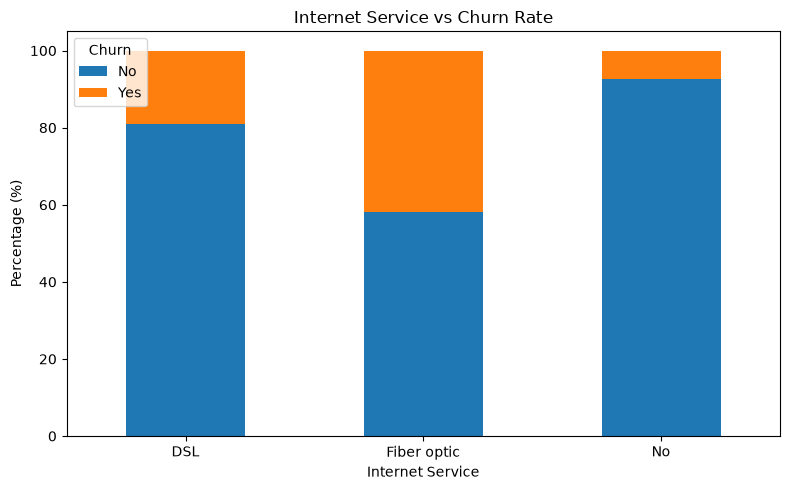

In [4]:
internet_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Internet Service vs Churn Rate")
plt.xlabel("Internet Service")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

ONLINE SECURITY VS CHURN


In [5]:
security_churn = pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
) * 100

print(security_churn.round(2))

Churn                   No    Yes
OnlineSecurity                   
No                   58.23  41.77
No internet service  92.60   7.40
Yes                  85.39  14.61


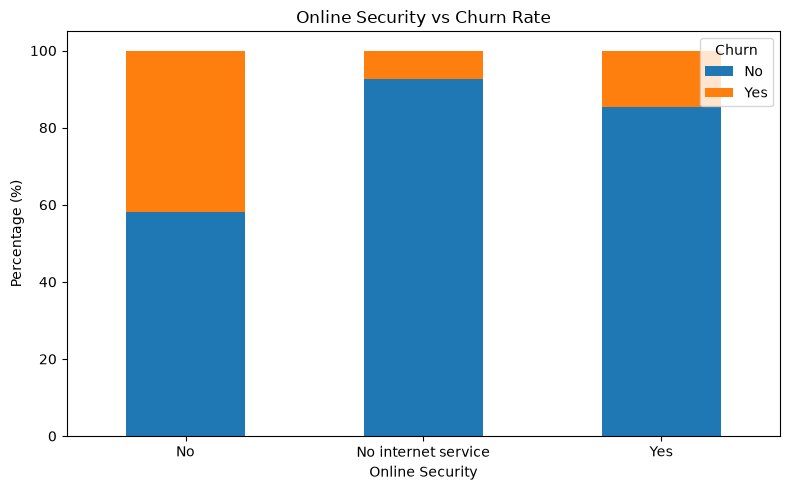

In [6]:
security_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Online Security vs Churn Rate")
plt.xlabel("Online Security")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

TECHSUPPORT VS CHURN

In [7]:
support_churn = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

print(support_churn.round(2))

Churn                   No    Yes
TechSupport                      
No                   58.36  41.64
No internet service  92.60   7.40
Yes                  84.83  15.17


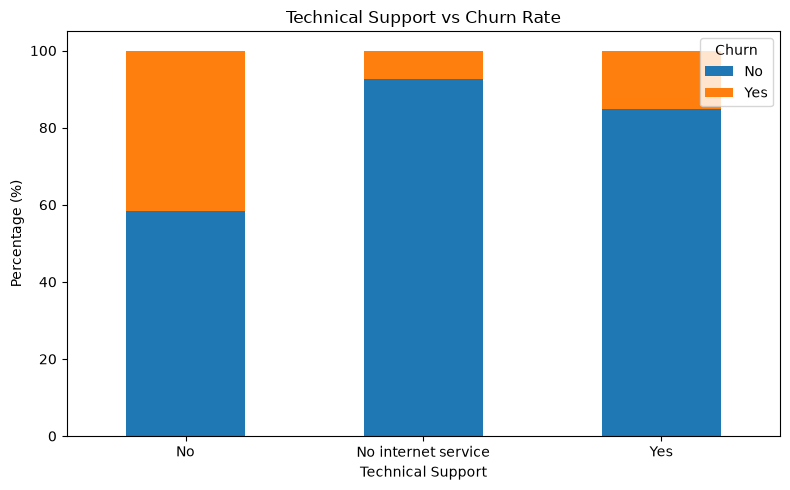

In [8]:
support_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Technical Support vs Churn Rate")
plt.xlabel("Technical Support")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

PAPERLESS BILLING VS CHURN

In [9]:
billing_churn = pd.crosstab(
    df["PaperlessBilling"],
    df["Churn"],
    normalize="index"
) * 100

print(billing_churn.round(2))

Churn                No    Yes
PaperlessBilling              
No                83.67  16.33
Yes               66.43  33.57


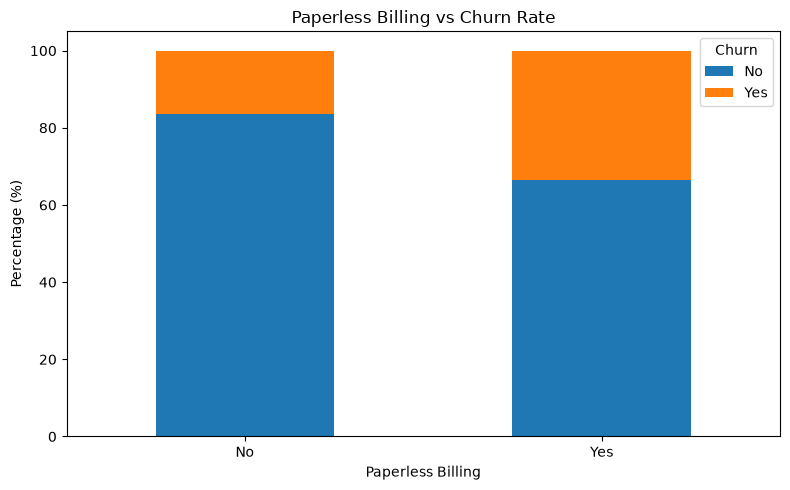

In [10]:
billing_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Paperless Billing vs Churn Rate")
plt.xlabel("Paperless Billing")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

SENIOR CITIZEN VS CHURN

In [11]:
senior_churn = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

print(senior_churn.round(2))

Churn             No    Yes
SeniorCitizen              
0              76.39  23.61
1              58.32  41.68


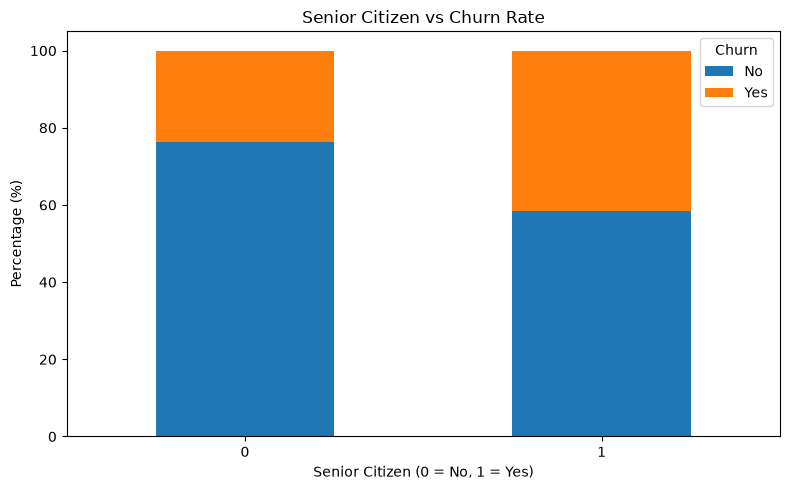

In [12]:
senior_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Senior Citizen vs Churn Rate")
plt.xlabel("Senior Citizen (0 = No, 1 = Yes)")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

CATEGORIAL FEATURE VS CHURN

In [13]:
def categorical_vs_churn(df, column):

    print(f"\nAnalysis of {column} vs Churn")

    # Customer count
    print("\nCustomer Count:")
    print(df[column].value_counts())

    # Churn count
    print("\nChurn Count:")
    print(pd.crosstab(df[column], df["Churn"]))

    # Churn percentage
    churn_percentage = pd.crosstab(
        df[column],
        df["Churn"],
        normalize="index"
    ) * 100

    print("\nChurn Percentage:")
    print(churn_percentage)

    # Visualization
    churn_percentage.plot(
        kind="bar",
        stacked=True,
        figsize=(8, 5)
    )

    plt.title(f"{column} vs Churn Percentage")
    plt.xlabel(column)
    plt.ylabel("Percentage")
    plt.xticks(rotation=0)
    plt.legend(title="Churn")
    plt.tight_layout()
    plt.show()


Analysis of OnlineSecurity vs Churn

Customer Count:
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

Churn Count:
Churn                  No   Yes
OnlineSecurity                 
No                   2037  1461
No internet service  1413   113
Yes                  1724   295

Churn Percentage:
Churn                       No        Yes
OnlineSecurity                           
No                   58.233276  41.766724
No internet service  92.595020   7.404980
Yes                  85.388806  14.611194


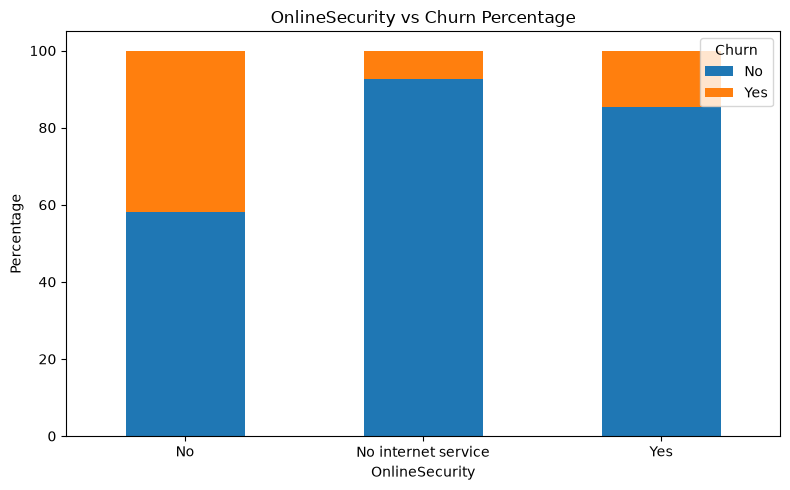

In [14]:
categorical_vs_churn(df, "OnlineSecurity")


Analysis of SeniorCitizen vs Churn

Customer Count:
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

Churn Count:
Churn            No   Yes
SeniorCitizen            
0              4508  1393
1               666   476

Churn Percentage:
Churn                 No        Yes
SeniorCitizen                      
0              76.393832  23.606168
1              58.318739  41.681261


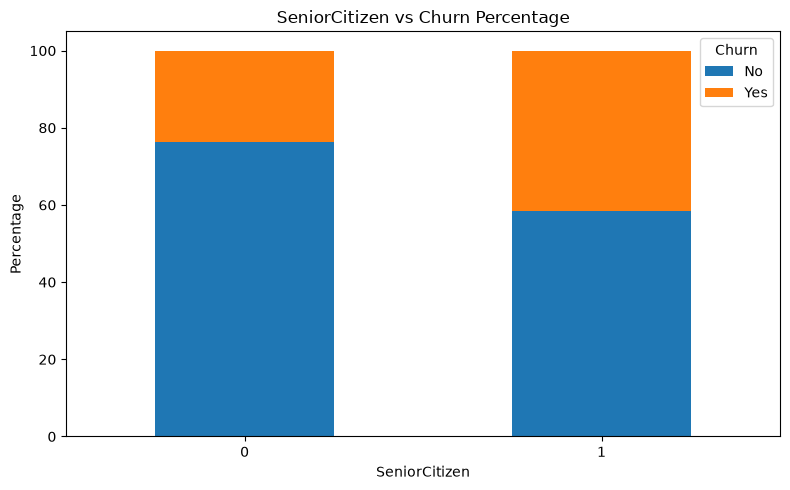

In [15]:
categorical_vs_churn(df, "SeniorCitizen")


Analysis of PaperlessBilling vs Churn

Customer Count:
PaperlessBilling
Yes    4171
No     2872
Name: count, dtype: int64

Churn Count:
Churn               No   Yes
PaperlessBilling            
No                2403   469
Yes               2771  1400

Churn Percentage:
Churn                    No        Yes
PaperlessBilling                      
No                83.669916  16.330084
Yes               66.434908  33.565092


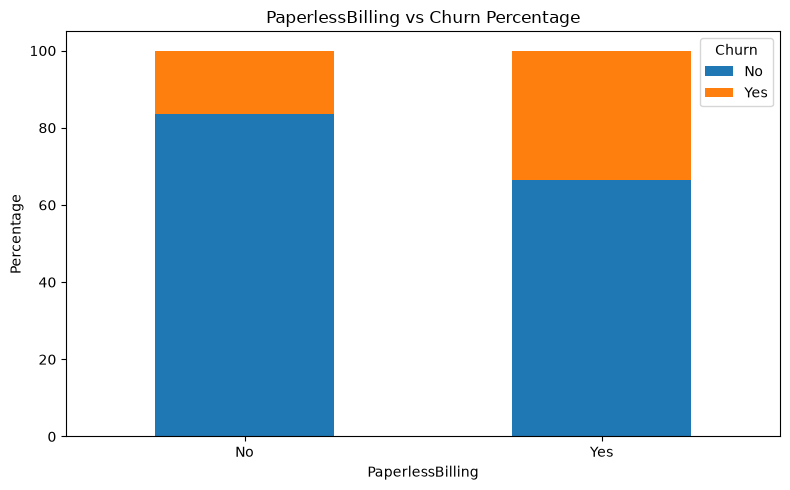

In [16]:
categorical_vs_churn(df, "PaperlessBilling")


Analysis of TechSupport vs Churn

Customer Count:
TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64

Churn Count:
Churn                  No   Yes
TechSupport                    
No                   2027  1446
No internet service  1413   113
Yes                  1734   310

Churn Percentage:
Churn                       No        Yes
TechSupport                              
No                   58.364526  41.635474
No internet service  92.595020   7.404980
Yes                  84.833659  15.166341


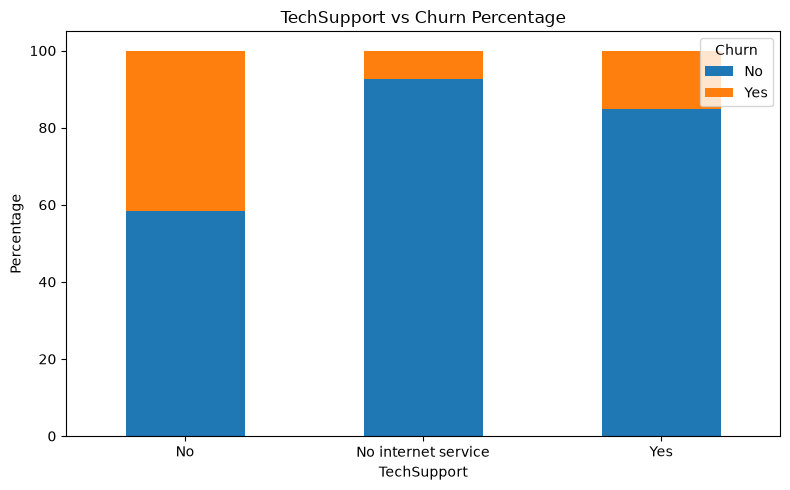

In [17]:
categorical_vs_churn(df, "TechSupport")

CO-RELATION ANALYSIS

In [18]:
df_corr = df.copy()

df_corr["Churn_Encoded"] = df_corr["Churn"].map({
    "No": 0,
    "Yes": 1
})

In [19]:
numerical_df = df_corr.select_dtypes(include=["int64", "float64"])

numerical_df.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn_Encoded
0,0,1,29.85,29.85,0
1,0,34,56.95,1889.50,0
2,0,2,53.85,108.15,1
3,0,45,42.30,1840.75,0
4,0,2,70.70,151.65,1


In [20]:

correlation_matrix = numerical_df.corr()

print(correlation_matrix)

                SeniorCitizen    tenure  MonthlyCharges  TotalCharges  \
SeniorCitizen        1.000000  0.016567        0.220173      0.103006   
tenure               0.016567  1.000000        0.247900      0.826178   
MonthlyCharges       0.220173  0.247900        1.000000      0.651174   
TotalCharges         0.103006  0.826178        0.651174      1.000000   
Churn_Encoded        0.150889 -0.352229        0.193356     -0.198324   

                Churn_Encoded  
SeniorCitizen        0.150889  
tenure              -0.352229  
MonthlyCharges       0.193356  
TotalCharges        -0.198324  
Churn_Encoded        1.000000  


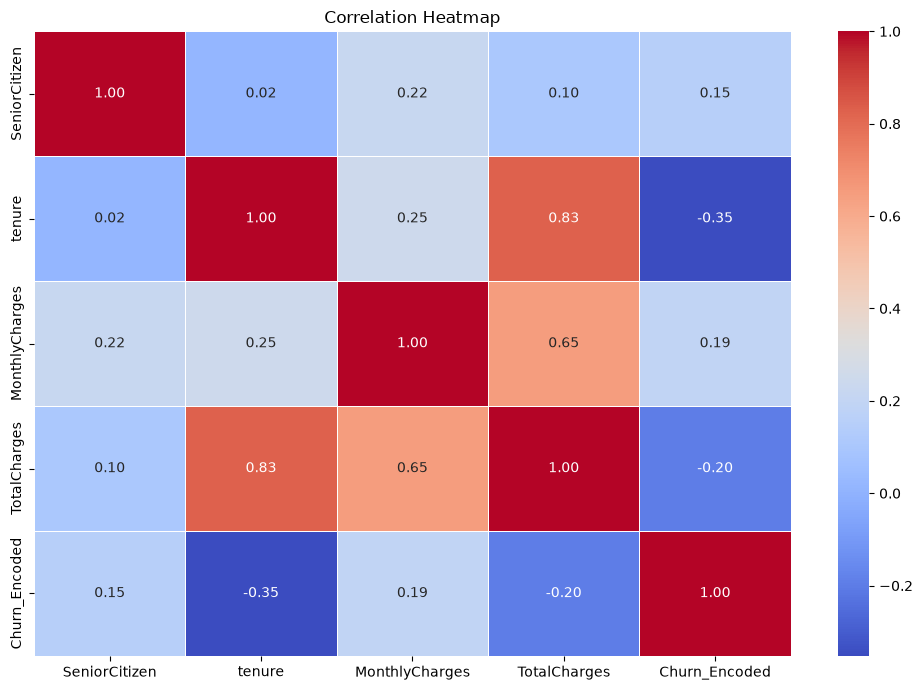

In [21]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [22]:
churn_correlation = correlation_matrix["Churn_Encoded"].sort_values(
    ascending=False
)

print(churn_correlation)

Churn_Encoded     1.000000
MonthlyCharges    0.193356
SeniorCitizen     0.150889
TotalCharges     -0.198324
tenure           -0.352229
Name: Churn_Encoded, dtype: float64


OUTLIER ANALYSIS

In [23]:
numerical_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

df[numerical_columns].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


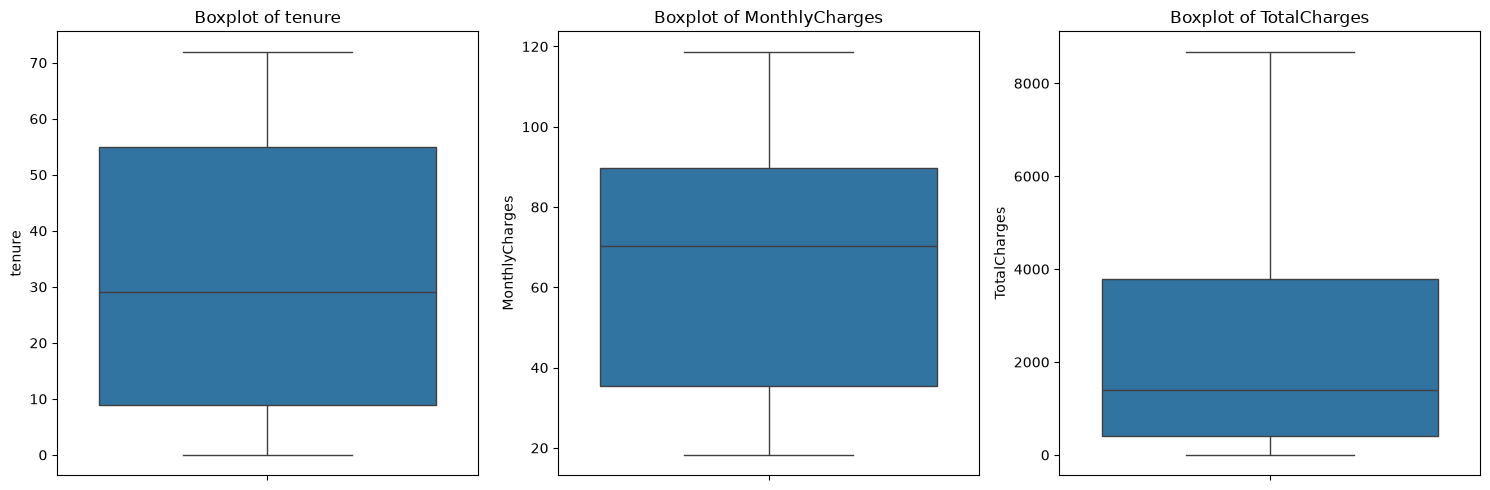

In [24]:
plt.figure(figsize=(15, 5))

for i, column in enumerate(numerical_columns, 1):

    plt.subplot(1, 3, i)

    sns.boxplot(y=df[column])

    plt.title(f"Boxplot of {column}")

plt.tight_layout()
plt.show()

In [25]:
for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    print(f"\nColumn: {column}")
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)
    print("Number of Outliers:", len(outliers))


Column: tenure
Lower Limit: -60.0
Upper Limit: 124.0
Number of Outliers: 0

Column: MonthlyCharges
Lower Limit: -46.02499999999999
Upper Limit: 171.375
Number of Outliers: 0

Column: TotalCharges
Lower Limit: -4683.525
Upper Limit: 8868.675
Number of Outliers: 0


In [26]:
for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outlier_mask = (
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    )

    print(f"\n{column} vs Churn")

    print(
        pd.crosstab(
            outlier_mask,
            df["Churn"],
            normalize="index"
        ) * 100
    )


tenure vs Churn
Churn          No        Yes
tenure                      
False   73.463013  26.536987

MonthlyCharges vs Churn
Churn                  No        Yes
MonthlyCharges                      
False           73.463013  26.536987

TotalCharges vs Churn
Churn                No        Yes
TotalCharges                      
False         73.463013  26.536987


STATISTICAL ANALYSIS

In [27]:
churn_groups = df.groupby("Churn")

churn_groups[["tenure", "MonthlyCharges", "TotalCharges"]].describe()

tenure                                                     \
        count       mean        std  min   25%   50%   75%   max   
Churn                                                              
No     5174.0  37.569965  24.113777  0.0  15.0  38.0  61.0  72.0   
Yes    1869.0  17.979133  19.531123  1.0   2.0  10.0  29.0  72.0   

      MonthlyCharges             ...               TotalCharges               \
               count       mean  ...   75%     max        count         mean   
Churn                            ...                                           
No            5174.0  61.265124  ...  88.4  118.75       5174.0  2549.911442   
Yes           1869.0  74.441332  ...  94.2  118.35       1869.0  1531.796094   

                                                              
               std    min    25%       50%      75%      max  
Churn                                                         
No     2329.954215   0.00  572.9  1679.525  4262.85  8672.45  
Yes    1890.822994  18.85  134.5   703.550  2331.30  8684.80  

[2 rows x 24 columns]

In [28]:
churn_groups[["tenure", "MonthlyCharges", "TotalCharges"]].mean()

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.569965,61.265124,2549.911442
Yes,17.979133,74.441332,1531.796094


In [29]:
churn_groups[["tenure", "MonthlyCharges", "TotalCharges"]].median()

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.425,1679.525
Yes,10.0,79.650,703.550


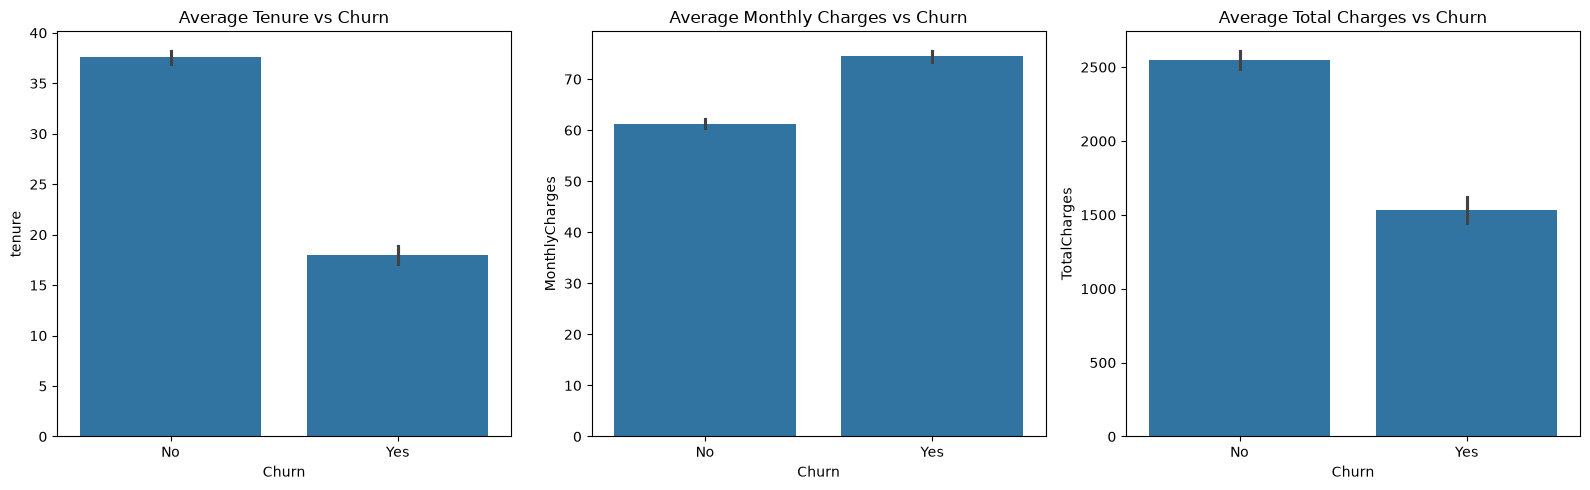

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.barplot(data=df, x="Churn", y="tenure", ax=axes[0])
axes[0].set_title("Average Tenure vs Churn")

sns.barplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1])
axes[1].set_title("Average Monthly Charges vs Churn")

sns.barplot(data=df, x="Churn", y="TotalCharges", ax=axes[2])
axes[2].set_title("Average Total Charges vs Churn")

plt.tight_layout()
plt.show()

In [32]:
from scipy.stats import ttest_ind

churned = df[df["Churn"] == "Yes"]["MonthlyCharges"]
retained = df[df["Churn"] == "No"]["MonthlyCharges"]

t_stat, p_value = ttest_ind(
    churned,
    retained,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Statistically significant difference")
else:
    print("No statistically significant difference")

T-statistic: 18.407526676414673
P-value: 8.592449331547067e-73
Statistically significant difference


MULTIVARIATE ANALYSIS

Tenure vs MonthlyCharges vs Churn

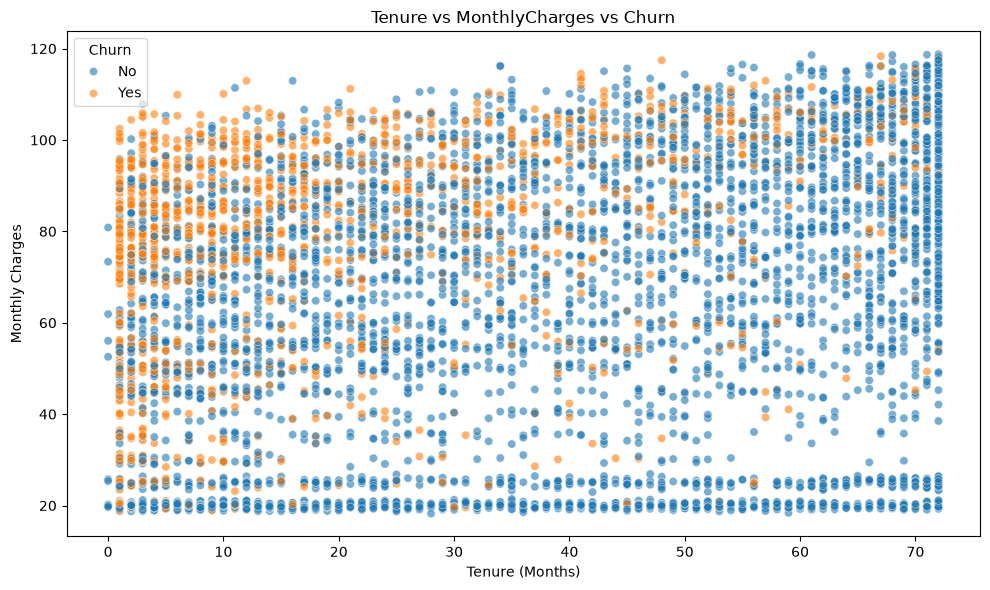

In [33]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="tenure",
    y="MonthlyCharges",
    hue="Churn",
    alpha=0.6
)

plt.title("Tenure vs MonthlyCharges vs Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

  Contract vs Tenure vs Churn  

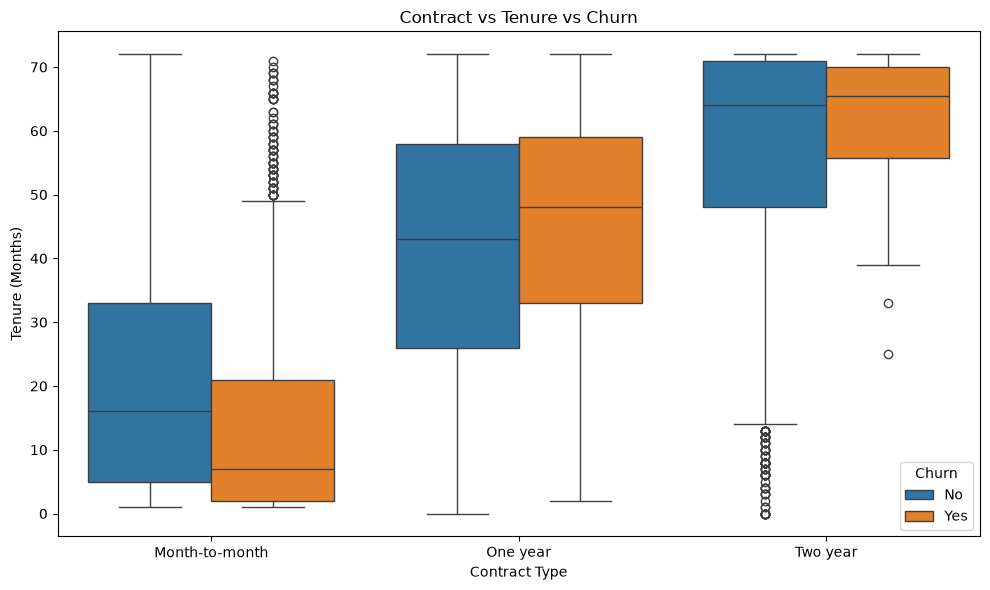

In [34]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Contract",
    y="tenure",
    hue="Churn"
)

plt.title("Contract vs Tenure vs Churn")
plt.xlabel("Contract Type")
plt.ylabel("Tenure (Months)")
plt.tight_layout()
plt.show()

InternetService vs MonthlyCharges vs Churn

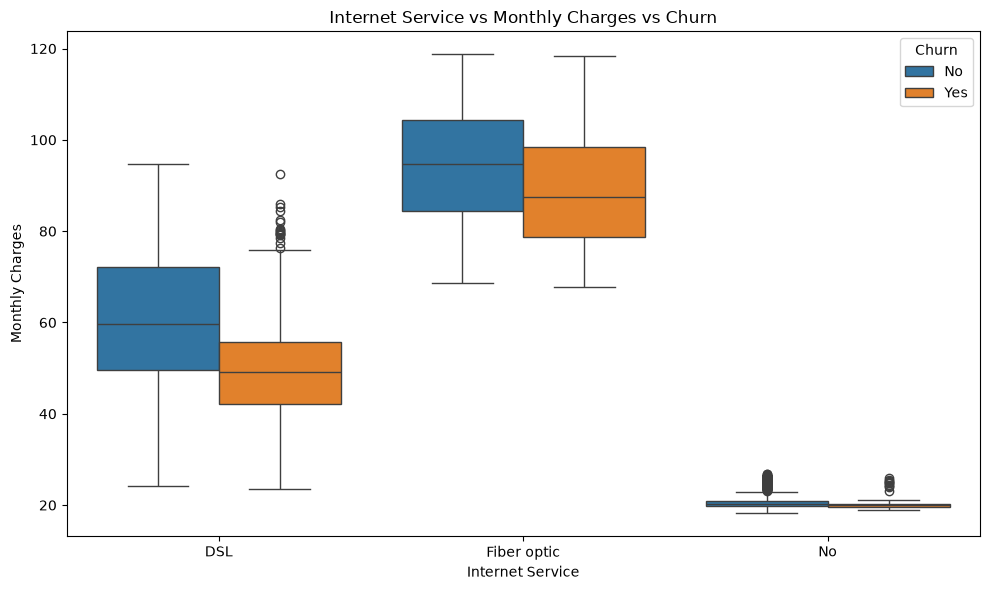

In [35]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="InternetService",
    y="MonthlyCharges",
    hue="Churn"
)

plt.title("Internet Service vs Monthly Charges vs Churn")
plt.xlabel("Internet Service")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

Tenure Group vs Contract vs Churn

In [37]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[0, 12, 24, 48, 72],
    labels=["0-12 Months", "13-24 Months", "25-48 Months", "49-72 Months"],
    include_lowest=True
)

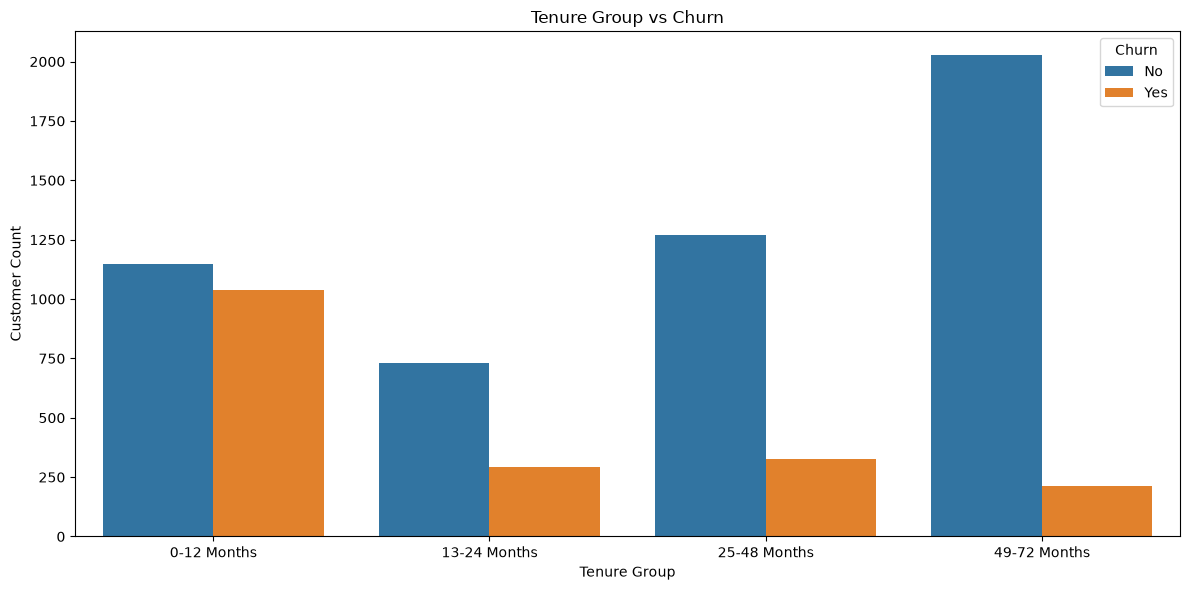

In [38]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="TenureGroup",
    hue="Churn"
)

plt.title("Tenure Group vs Churn")
plt.xlabel("Tenure Group")
plt.ylabel("Customer Count")
plt.tight_layout()
plt.show()